In [1]:
import numpy as np
import matplotlib.pyplot as plt
from astropy.io import fits

In [2]:
#read final stacked images
filters = ["red","green","blue"]
data = {}
for filter in filters:
    filename = "data_prefiltered/final_aligned_" + filter + ".fits"
    data[filter] = fits.getdata(filename)
    print("Loaded " + filename)


Loaded data_prefiltered/final_aligned_red.fits
Loaded data_prefiltered/final_aligned_green.fits
Loaded data_prefiltered/final_aligned_blue.fits


In [3]:
#adjust weights corresponding to normailzed zero point fluxes (analysis_data_prefiltered_v2_vul12.ipynb)
weights = {"red":0.66902763, "green":0.73612506, "blue":1.0}
for filter in filters:
    data[filter] = data[filter]*weights[filter]
    print("Applied weight to " + filter + ": ", weights[filter])

Applied weight to red:  0.66902763
Applied weight to green:  0.73612506
Applied weight to blue:  1.0


In [5]:
#need log scale in order to see anything
def scale_log(channel, vmin=None, vmax=None):
    channel = np.array(channel, dtype=float)
    # log stretch
    scaled = (np.log(channel.clip(vmin, vmax)) - np.log(vmin)) / (np.log(vmax) - np.log(vmin))
    return scaled

#set negatives to zero
def delete_neg(im):
    for i in range(len(im)):
        for j in range(len(im[0])):
            if im[i][j] < 1 :
                im[i][j] = 1
    return im

In [21]:
#set negatives to 1
for filter in filters:
    data[filter] = delete_neg(data[filter])
    print("Set negatives to 1 for " + filter)

#scale each channel
vmin = min([np.min(data[filter]) for filter in filters])
vmax = max([np.max(data[filter]) for filter in filters])
for filter in filters:
    data[filter] = scale_log(data[filter], vmin=vmin, vmax=vmax)
    print("Scaled " + filter)


Set negatives to 1 for red
Set negatives to 1 for green
Set negatives to 1 for blue
Scaled red
Scaled green
Scaled blue


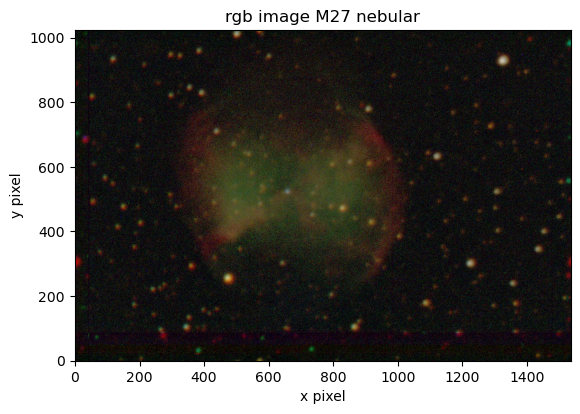

In [ ]:
#stack to actual rgb image and show
rgb_image = np.dstack([data[filter] for filter in filters])
plt.imshow(rgb_image,origin = "lower")

plt.title("rgb image M27 nebular")
plt.xlabel("x pixel")
plt.ylabel("y pixel")
#plt.savefig("m27_rgb_image_ZPcorrected.png")
plt.show()